In [23]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [24]:
### Tools- Internet search
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str,max_results:int=5,
topic: Literal["general","sports","news","finance"]="general",
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)



In [25]:
from langchain.chat_models import init_chat_model

model = init_chat_model("groq:qwen/qwen3.8-27b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, client=<groq.resources.chat.completions.Completions object at 0x0000022DEF3F7E30>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000022DF05C0830>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

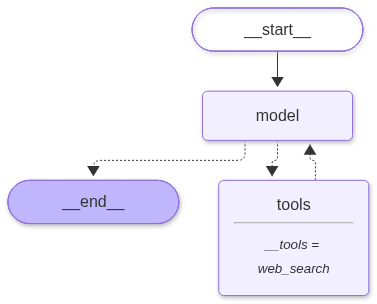

In [26]:
from langchain.agents import create_agent

simple_agent = create_agent(
    model=model,
    tools=[web_search],

)

simple_agent

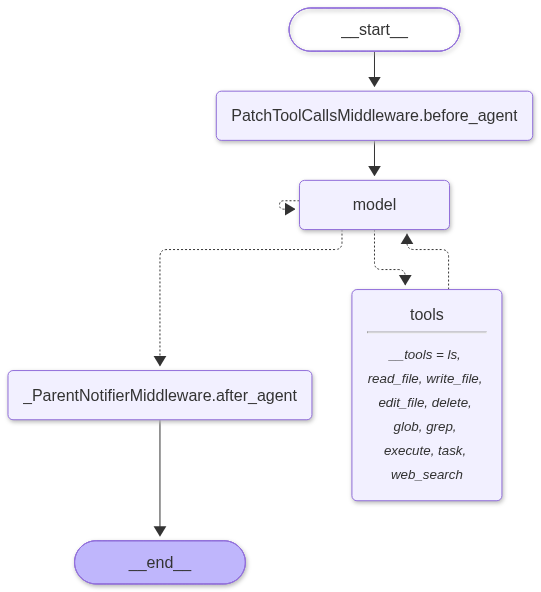

In [27]:
### Create a deep agent
## Prompt

## agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [34]:
results = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
results

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='42c9f82a-1028-4b38-924b-09d244c1fa38'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'arjzc2fdg', 'function': {'arguments': '{"query":"deepagent"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 2850, 'total_tokens': 2877, 'completion_time': 0.073168123, 'completion_tokens_details': None, 'prompt_time': 0.206665261, 'prompt_tokens_details': None, 'queue_time': 0.050659486, 'total_time': 0.279833384}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c4da-30ec-73e7-aa1d-29a6c909c8a3-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'deepagent'}, 'id': 'arjzc2fdg', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens':

In [35]:
results["messages"][-1].content

'There are two distinct things called "DeepAgent":\n\n**1. Deep Agents (LangChain/LangGraph) — the most prominent match**\nAn open-source agent harness by the LangChain team for complex, multi-step agent work.\n- **What it is:** A "batteries-included" agent framework that runs out of the box but lets you extend, override, or replace any piece.\n- **Key capabilities:**\n  - **Planning tools** — agents decompose tasks, track progress, and adapt\n  - **Subagent spawning** — delegate independent subtasks in parallel, each with isolated context\n  - **Virtual filesystem** — persists system prompts, skills, and long-term memory across sessions\n  - **Context management** — for long-running tasks like research and coding\n- **Relationship to other tools:** Built on LangGraph (the graph runtime), sits above LangChain\'s `create_agent` (a minimal harness), and pairs with LangSmith for tracing, evaluation, and monitoring.\n- **Two ways to run it:** *Managed Deep Agents* (LangSmith runs the infra

In [40]:
results['files']

{}

### What happened?

Your deep agent automatically:
- Planned its approach: Used the built-in write_todos tool to break down the research task
- Conducted research: Called the internet_search tool to gather information
- Managed context: Used file system tools (write_file, read_file) to offload large search results
- Spawned subagents (if needed): Delegated complex subtasks to specialized subagents
- Synthesized a report: Compiled findings into a coherent response

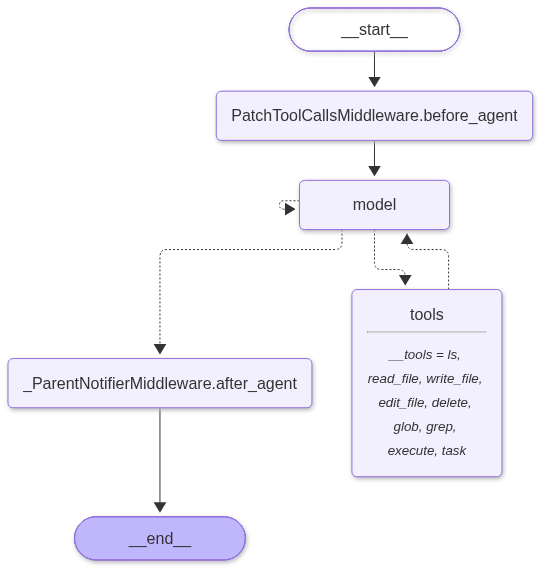

In [41]:
from langchain.chat_models import init_chat_model
from deepagents import create_deep_agent

model = init_chat_model(model='gpt-5')
agent = create_deep_agent(model=model)
agent

In [38]:
result  = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='63fd7ebf-4f45-4581-b626-5524220ad4db'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'm8n6ymync', 'function': {'arguments': '{"path":"/"}', 'name': 'ls'}, 'type': 'function'}, {'id': 'mn9f5r3bx', 'function': {'arguments': '{"output_mode":"files_with_matches","pattern":"deepagent"}', 'name': 'grep'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 77, 'prompt_tokens': 2726, 'total_tokens': 2803, 'completion_time': 0.153282014, 'completion_tokens_details': None, 'prompt_time': 0.207116414, 'prompt_tokens_details': None, 'queue_time': 0.063648447, 'total_time': 0.360398428}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c4e8-5227-7770-b63b-8c82967a66f7-0', tool_calls=[{'name': 'ls', 'args':

### System Prompt
Deep agents come with a built-in system prompt inspired by Claude Code’s system prompt. The default system prompt contains detailed instructions for using the built-in planning tool, file system tools, and subagents.
Each deep agent tailored to a use case should include a custom system prompt specific to that use case.

In [43]:
from deepagents import create_deep_agent

research_instructions =   """\
    you are a expert researcher. your job is to conduct \
    throught research, and then wrirte a polished report. \
"""

agent = create_deep_agent(
    model=model,
    
    system_prompt=research_instructions
)
results = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
results

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='0e02be85-4869-4aa2-87e9-82180169670d'),
  AIMessage(content='Could you clarify which “deepagent” you mean? The name is used for several different things, for example:\n- An open-source deep reinforcement learning “DeepAgent” repo/framework (there are a few on GitHub).\n- A conversational/AI agent Python package with a similar name on PyPI/GitHub.\n- A security/endpoint agent branding used by some vendors.\n- Research projects/papers nicknamed “DeepAgent.”\n\nIf you can share a link, context (library, company product, research paper), or the platform you saw it on, I can give a precise explanation.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 832, 'prompt_tokens': 2103, 'total_tokens': 2935, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 704, 'rejected_prediction_tokens': 0, 'text

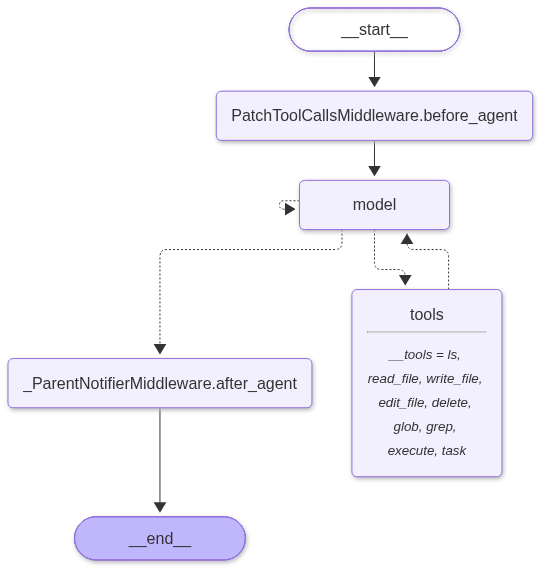

In [44]:
agent

In [50]:
import os
from typing import Literal
from deepagents import create_deep_agent
from tavily import TavilyClient

tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def internet_search(
        query: str,
        max_results: int = 5,
        topic: Literal["general", "news", "finance"] = "general",
        include_raw_content: bool = False
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic
    )

result = agent.invoke({"messages":[{"role":"user","content":"What is deep agent in Agentic AI?"}]})
result

{'messages': [HumanMessage(content='What is deep agent in Agentic AI?', additional_kwargs={}, response_metadata={}, id='5d70e064-f97d-43dd-9505-d40052f1c077'),
  AIMessage(content='A deep agent is an agentic AI system designed to tackle long, complex tasks by reasoning and acting through many iterative layers (depth) of planning, execution, and verification, rather than a single prompt-and-reply. Depth here means multiple thought–action–observation cycles, often with hierarchical subgoals, self-critique, and retries.\n\nWhat makes it “deep”\n- Multi-step control loop: plans, takes actions with tools, observes results, revises the plan, and repeats—often dozens or hundreds of steps if needed.\n- Hierarchical structure: a top-level planner delegates to specialized subagents or skills for research, coding, analysis, or writing.\n- Verification and reflection: separate critic/evaluator steps test code, check claims, compare sources, or vote among candidates to reduce errors.\n- Persistent 

In [51]:
results["messages"][-1].content

'Could you clarify which “deepagent” you mean? The name is used for several different things, for example:\n- An open-source deep reinforcement learning “DeepAgent” repo/framework (there are a few on GitHub).\n- A conversational/AI agent Python package with a similar name on PyPI/GitHub.\n- A security/endpoint agent branding used by some vendors.\n- Research projects/papers nicknamed “DeepAgent.”\n\nIf you can share a link, context (library, company product, research paper), or the platform you saw it on, I can give a precise explanation.'